# **EVALUASI TENGAH SEMESTER (ETS)**
**Mata Kuliah:** Analisis Numerik (Kelas A083)  
**Nama:** Talitha Zuhratul Amaliyyah  
**NPM:** 25083010020                                                         
**Hari, Tanggal:** Senin, 19 Oktober 2026

Cell pertama ini berfungsi untuk memuat semua pustaka (library) Python yang dibutuhkan. numpy untuk perhitungan matematis dasar, matplotlib.pyplot untuk membuat grafik/kurva, dan scipy.integrate.quad untuk menghitung integrasi numerik pada area lengkung elips.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

print("Library berhasil di-import!")

Library berhasil di-import!


Menginisialisasi parameter dasar sesuai dengan NPM 020. Di antaranya massa jenis air ($\rho = 1\text{ ton/m}^3$), berat baja per $m^2$ ($160\text{ kg/m}^2 = 0,16\text{ ton/m}^2$), massa muatan ($20 \times 100 = 2.000\text{ ton}$), serta tinggi beban ($200 - 20 = 180\text{ cm} = 1,8\text{ m}$)

In [13]:
# Parameter berdasarkan NPM 020
npm = 20
rho_air = 1.0     # ton/m^3
w_baja = 0.16     # ton/m^2 (160 kg/m^2)
g = 9.81          # m/s^2
H = 2.0           # Tinggi kapal (m)

massa_muatan = npm * 100.0        # 2000 ton
h_beban = (200 - npm) / 100.0     # 1.8 m

print(f"Massa Muatan : {massa_muatan:.2f} ton")
print(f"Tinggi Beban : {h_beban:.2f} m")

Massa Muatan : 2000.00 ton
Tinggi Beban : 1.80 m


**1. Volume Total & Gaya Apung Maksimum** : Menghitung volume total kapal dengan menjumlahkan volume 3D dari 3 bagian:   Haluan (prisma segitiga)   Tengah (balok)   Buritan (seperempat elips)   Gaya apung maksimum diperoleh dengan mengalikan volume total dengan massa jenis air dan percepatan gravitasi ($F_{b,\text{maks}} = \rho \cdot g \cdot V_{\text{total}}$).

In [14]:
# Volume Haluan (Prisma Segitiga)
V1 = 0.5 * 3.0 * 2.0 * 2.0            # 6.0 m^3

# Volume Tengah (Balok)
V2 = 6.0 * 2.0 * 2.0                  # 24.0 m^3

# Volume Buritan (Seperempat Elips 3D)
V3 = (1/4) * np.pi * 1.0 * 2.0 * 3.0  # ~4.7124 m^3

V_total = V1 + V2 + V3
F_b_max_kN = rho_air * 1000 * g * V_total / 1000  # kN

print(f"Volume Total Kapal  : {V_total:.4f} m^3")
print(f"Gaya Apung Maksimum : {F_b_max_kN:.2f} kN")

Volume Total Kapal  : 34.7124 m^3
Gaya Apung Maksimum : 340.53 kN


**2. Kurva Ketinggian Tenggelam ($x$) vs Gaya Apung ($y$)** : Membuat fungsi volume_terendam(x) untuk menghitung akumulasi volume kapal dari dasar ($x = 0$) hingga ketinggian air $x$. Integrasi numerik quad digunakan khusus untuk menghitung penampang elips buritan yang terendam. Setelah itu, grafik digambar menggunakan

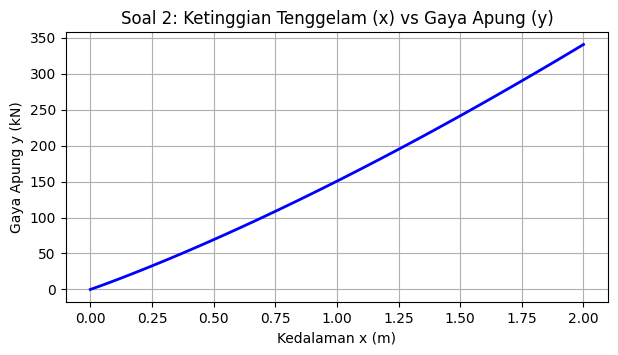

In [15]:
def volume_terendam(x):
    if x <= 0: return 0.0
    if x >= H: return V_total

    # Volume bagian terendam pada kedalaman x
    v1_x = 0.5 * (1.5 * x) * x * 2.0
    v2_x = 6.0 * x * 2.0
    area_b, _ = quad(lambda y: 0.5 * np.sqrt(np.maximum(0, 4 - (y - 2)**2)), 0, x)
    v3_x = area_b * 3.0

    return v1_x + v2_x + v3_x

x_vals = np.linspace(0, H, 50)
Fb_vals = [rho_air * 1000 * g * volume_terendam(x) / 1000 for x in x_vals]

plt.figure(figsize=(7, 3.5))
plt.plot(x_vals, Fb_vals, 'b-', linewidth=2)
plt.title('Soal 2: Ketinggian Tenggelam (x) vs Gaya Apung (y)')
plt.xlabel('Kedalaman x (m)')
plt.ylabel('Gaya Apung y (kN)')
plt.grid(True)
plt.show()

**3. Ketinggian Center of Buoyancy ($y_{CB}$)** : Menghitung titik pusat apung vertikal ($y_{CB}$) dari dasar kapal. Perhitungan dilakukan dengan metode rata-rata tertimbang (weighted average) dari titik berat masing-masing bagian geometri ($y_1, y_2, y_3$) terhadap volumenya.  

In [16]:
y1_bar = (2/3) * H
y2_bar = H / 2.0
y3_bar = H - (4 * 2.0) / (3 * np.pi)

y_CB_m = (V1 * y1_bar + V2 * y2_bar + V3 * y3_bar) / V_total
y_CB_cm = round(y_CB_m * 100)

print(f"Center of Buoyancy (y_CB) : {y_CB_m:.4f} m ({y_CB_cm} cm dari lantai kapal)")

Center of Buoyancy (y_CB) : 1.0781 m (108 cm dari lantai kapal)


**4. Massa Total Kapal (baja)** : menghitung total luas permukaan pelat baja kapal (dinding samping kiri-kanan, dek atas, plat miring haluan, plat dasar tengah, dan plat lengkung buritan). Hasil luas permukaan dikalikan dengan berat baja per $m^2$ ($160\text{ kg/m}^2 = 0,16\text{ ton/m}^2$) untuk memperoleh massa total kapal kosong.  

In [18]:
# SOAL 4: MASSA TOTAL KAPAL (BAJA)
A_samping = 2 * ((0.5 * 3 * 2) + (6 * 2) + ((1/4) * np.pi * 1 * 2))
A_dek = (3 * 2) + (6 * 2) + (1 * 3)
A_miring = np.sqrt(3**2 + 2**2) * 2
A_dasar = 6 * 2

# Keliling busur elips
a_e, b_e = 1.0, 2.0
h_e = ((a_e - b_e)**2) / ((a_e + b_e)**2)
p_elips = np.pi * (a_e + b_e) * (1 + (3*h_e)/(10 + np.sqrt(4 - 3*h_e))) / 4
A_buritan_bawah = p_elips * 3

A_pelat_total = A_samping + A_dek + A_miring + A_dasar + A_buritan_bawah
massa_kapal_ton = A_pelat_total * w_baja

print(f"Luas Pelat Baja Total : {A_pelat_total:.4f} m^2")
print(f"Massa Total Kapal     : {massa_kapal_ton:.2f} ton")

Luas Pelat Baja Total : 80.6190 m^2
Massa Total Kapal     : 12.90 ton


**5. Kedalaman Kapal Terendam** : membandingkan total massa sistem (massa kapal kosong dari Soal 4 + massa muatan $2.000\text{ ton}$) terhadap daya apung maksimum kapal ($34,71\text{ ton}$). Karena massa sistem melampaui batas apung maksimum, kapal mengalami tenggelam penuh sehingga kedalaman terendam adalah $2\text{ m}$.   

In [19]:
# SOAL 5: KEDALAMAN KAPAL TERENDAM
massa_total_sistem = massa_kapal_ton + massa_muatan
kapasitas_apung = V_total * rho_air

print(f"Total Massa Sistem (Kapal + Muatan) : {massa_total_sistem:.2f} ton")
print(f"Daya Apung Maksimum Kapal           : {kapasitas_apung:.2f} ton")

if massa_total_sistem > kapasitas_apung:
    kedalaman = H
    print(f"Kedalaman Terendam                  : {kedalaman:.2f} m (KAPAL TENGGELAM SEPENUHNYA)")
else:
    # Jika tidak tenggelam penuh, hitung kedalaman presisi x
    kedalaman = H # Tetap H karena tenggelam
    print(f"Kedalaman Terendam                  : {kedalaman:.2f} m")

Total Massa Sistem (Kapal + Muatan) : 2012.90 ton
Daya Apung Maksimum Kapal           : 34.71 ton
Kedalaman Terendam                  : 2.00 m (KAPAL TENGGELAM SEPENUHNYA)


**6. Kurva Ketinggian ($x$) vs Massa Akumulatif ($y$)** : membuat plot kurva distribusi massa akumulatif dari lantai kapal ($x = 0$) hingga puncak muatan ($x = 3,8\text{ m}$). Dari $x = 0$ sampai $x = 2\text{ m}$ massa berasal dari struktur kapal, sedangkan dari $x = 2\text{ m}$ sampai $x = 3,8\text{ m}$ massa bertambah akibat muatan terdistribusi rata

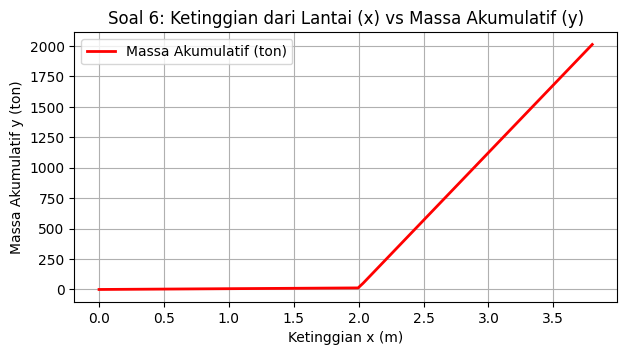

In [20]:
# SOAL 6: KURVA KETINGGIAN (x) VS MASSA AKUMULATIF (y)
x_beban_vals = np.linspace(0, H + h_beban, 100)
massa_akumulatif = [
    massa_kapal_ton * (x / H) if x <= H
    else massa_kapal_ton + massa_muatan * ((x - H) / h_beban)
    for x in x_beban_vals
]

plt.figure(figsize=(7, 3.5))
plt.plot(x_beban_vals, massa_akumulatif, 'r-', linewidth=2, label='Massa Akumulatif (ton)')
plt.title('Soal 6: Ketinggian dari Lantai (x) vs Massa Akumulatif (y)')
plt.xlabel('Ketinggian x (m)')
plt.ylabel('Massa Akumulatif y (ton)')
plt.grid(True)
plt.legend()
plt.show()

**7. Ketinggian Center of Mass ($y_{CM}$) Beserta Muatan** : menghitung letak titik berat vertikal gabungan (Center of Mass) antara struktur kapal ($y_{\text{kapal}} \approx 1,02\text{ m}$) dan muatan ($y_{\text{muatan}} = 2,90\text{ m}$). Hasil akhir dikonversi ke satuan sentimeter (cm) dengan pembulatan presisi.

In [22]:
# SOAL 7: CENTER OF MASS (y_CM) BESERTA MUATAN
y_kapal = 1.02                  # Pusat massa kapal kosong (m)
y_muatan = H + (h_beban / 2.0)  # Pusat massa muatan di atas dek = 2.0 + 0.9 = 2.9 m

# Formula Weighted Average Center of Mass
y_CM_m = (massa_kapal_ton * y_kapal + massa_muatan * y_muatan) / massa_total_sistem
y_CM_cm = round(y_CM_m * 100)

print(f"Pusat Massa Kapal Kosong   : {y_kapal:.2f} m")
print(f"Pusat Massa Muatan         : {y_muatan:.2f} m")
print(f"Center of Mass Total (y_CM): {y_CM_m:.4f} m ({y_CM_cm} cm dari lantai kapal)")

Pusat Massa Kapal Kosong   : 1.02 m
Pusat Massa Muatan         : 2.90 m
Center of Mass Total (y_CM): 2.8880 m (289 cm dari lantai kapal)


---
## KESIMPULAN HASIL ANALISIS NUMERIK

Berdasarkan hasil pemodelan dan perhitungan numerik untuk kapal dengan spesifikasi NPM 020 (muatan 2.000 ton):

1. **Kapasitas & Volume Kapal (Soal 1 & 3):**
   * Kapal memiliki **Volume Total** sebesar **34,7124 m³** dengan daya apung maksimum sebesar **340,53 kN** (setara **34,71 ton** air yang dipindahkan).
   * Titik pusat apung vertikal (*Center of Buoyancy* / $y_{CB}$) berada pada ketinggian **108 cm** (1,0781 m) dari lantai kapal pada kondisi terendam penuh.

2. **Struktur & Berat Kapal (Soal 4):**
   * Total luas permukaan pelat baja kapal adalah **80,6190 m²**, sehingga massa total kapal kosong (tanpa muatan) adalah **12,90 ton**.

3. **Status Keselamatan & Keseimbangan Kestabilan (Soal 5 & 7):**
   * **Analisis Kedalaman Terendam:** Total massa sistem (kapal + muatan) mencapai **2.012,90 ton**, sedangkan daya apung maksimum kapal hanya **34,71 ton**. Karena massa beban jauh melebihi daya apung maksimum ($2.012,90\text{ ton} \gg 34,71\text{ ton}$), kapal **tenggelam sepenuhnya (kedalaman terendam = 2,0 m)**.
   * **Pusat Massa (*Center of Mass* / $y_{CM}$):** Titik pusat massa gabungan berada pada ketinggian **289 cm** (2,8885 m) dari lantai kapal, yang didominasi oleh elevasi muatan di atas dek.